# R6 - Selección de la combinación arquitectura CNN + representación de entrada

**Candidatas (6 combinaciones operativas)**

- Arquitecturas: ResNet50, DenseNet121 y ConvNeXt-Tiny.
- Condiciones: **A** (imagen completa) y **B** (ROI automática obtenida con el segmentador U-Net fijo).
- La condición **C** (ROI de referencia) queda excluida: requiere la máscara de referencia, no está disponible en un uso real.

**Regla de selección (IOV aprobado)**

> "La configuración seleccionada es la de mayor AP media entre semillas, con criterio de desempate definido antes de ejecutar."

1. Criterio principal: mayor Average Precision (AP) media en `validation` (media de las 3 semillas).
2. Criterios complementarios, que se reportan pero no modifican la selección: ROC-AUC, sensibilidad, especificidad (umbral 0.5) y desviación estándar entre semillas.
3. Accuracy no se utiliza como criterio, por el desbalance de clases.

In [3]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


def locate_project_root() -> Path:
    current_dir = Path.cwd().resolve()

    for candidate in [current_dir, *current_dir.parents]:
        if ( (candidate / "src").exists() and (candidate / "data").exists() ):
            return candidate

    raise FileNotFoundError( "No se pudo localizar la raíz del proyecto." )


PROJECT_ROOT = locate_project_root()

## 1. Configuración y fuentes

Todo se lee en modo solo lectura: no se entrenan modelos y no se utiliza `test`.

In [4]:
CLASSIFICATION_DIR = PROJECT_ROOT / "results" / "classification"
R4_DIR = CLASSIFICATION_DIR / "r4_benchmark" / "analysis"
R5_DIR = CLASSIFICATION_DIR / "r5_input_representation" / "analysis"
OUTPUT_DIR = CLASSIFICATION_DIR / "r6_model_selection"
FIGURES_DIR = OUTPUT_DIR / "figures"
SPLIT_MANIFEST = PROJECT_ROOT / "configs" / "splits" / "mmotu_experimental_split.csv"

ARCHS = ["resnet50", "densenet121", "convnext_tiny"]
SELECTION_CONDITIONS = ["A", "B"]  # C excluida de la selección
SEEDS = [42, 43, 44]

PRIMARY_METRIC = "average_precision"
REPORTED_METRICS = ["average_precision", "roc_auc", "sensitivity", "specificity"]
THRESHOLD = 0.5
TOL = 1e-12

ARCH_LABELS = {"resnet50": "ResNet50", "densenet121": "DenseNet121", "convnext_tiny": "ConvNeXt-Tiny"}
CONDITION_LABELS = {"A": "A (imagen completa)", "B": "B (ROI automática)"}
METRIC_LABELS = {
    "roc_auc": "ROC-AUC",
    "average_precision": "AP",
    "sensitivity": "Sensibilidad",
    "specificity": "Especificidad",
}
RUN_SOURCES = {"A": "r4_benchmark", "B": "r5_input_representation"}
CLASS_LABELS = ["Benigno", "Maligno"]

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Paleta académica para las figuras de R6
PLOT_COLORS = {
    "selected": "#1F4E79", 
    "runner_up": "#C27A3C",
    "other": "#82909D", 
    "grid": "#DCE3EA", 
    "seed": {
        42: "#1F4E79",        
        43: "#268774",       
        44: "#C27A3C",       
    },
}

r4_summary = pd.read_csv(R4_DIR / "r4_architecture_summary.csv")
r5_summary = pd.read_csv(R5_DIR / "r5_condition_summary.csv")
r5_per_seed = pd.read_csv(R5_DIR / "r5_metrics_per_seed.csv")

# Solo se conservan las filas de validation de la partición (200 imágenes)
split_manifest = pd.read_csv(SPLIT_MANIFEST, usecols=["image_id", "binary_label", "experimental_split"])
validation_manifest = split_manifest[split_manifest["experimental_split"] == "validation"].set_index("image_id")
del split_manifest
assert len(validation_manifest) == 200

## 2. Tabla de las seis combinaciones operativas

Valores de `validation`: media ± desviación estándar entre las 3 semillas. La tabla se ordena por AP media de mayor a menor, que es el criterio principal del IOV. Los IC 95 % son los bootstrap ya calculados en R4/R5; no se recalculan.

In [5]:
candidates_long = r5_summary[r5_summary["condition"].isin(SELECTION_CONDITIONS)]
assert set(candidates_long["condition"]) == set(SELECTION_CONDITIONS)

candidates = candidates_long.pivot(
    index=["architecture", "condition"],
    columns="metric",
    values=["mean", "std_between_seeds", "ci95_lower", "ci95_upper"],
)
candidates.columns = [f"{metric}_{statistic}" for statistic, metric in candidates.columns]
candidates = candidates.reset_index()
assert len(candidates) == len(ARCHS) * len(SELECTION_CONDITIONS) == 6

candidates = candidates.sort_values(f"{PRIMARY_METRIC}_mean", ascending=False).reset_index(drop=True)
candidates.insert(0, "order_by_ap", np.arange(1, len(candidates) + 1))


def mean_sd(row, metric):
    return f"{row[f'{metric}_mean']:.3f} ± {row[f'{metric}_std_between_seeds']:.3f}"


compact_table = pd.DataFrame(
    {
        "Arquitectura": candidates["architecture"].map(ARCH_LABELS),
        "Condición": candidates["condition"].map(CONDITION_LABELS),
        "AP media ± DE": candidates.apply(mean_sd, axis=1, metric="average_precision"),
        "ROC-AUC media ± DE": candidates.apply(mean_sd, axis=1, metric="roc_auc"),
        "Sensibilidad media ± DE": candidates.apply(mean_sd, axis=1, metric="sensitivity"),
        "Especificidad media ± DE": candidates.apply(mean_sd, axis=1, metric="specificity"),
        "IC 95 % AP": candidates.apply(
            lambda row: f"[{row['average_precision_ci95_lower']:.3f}, {row['average_precision_ci95_upper']:.3f}]", axis=1
        ),
    }
)

candidates.to_csv(OUTPUT_DIR / "r6_candidates.csv", index=False)
compact_table.to_csv(OUTPUT_DIR / "r6_candidates_compact.csv", index=False)

compact_table

,Arquitectura,Condición,AP media ± DE,ROC-AUC media ± DE,Sensibilidad media ± DE,Especificidad media ± DE,IC 95 % AP
0,ConvNeXt-Tiny,A (imagen completa),0.541 ± 0.044,0.843 ± 0.037,0.455 ± 0.276,0.916 ± 0.122,"[0.381, 0.700]"
1,DenseNet121,A (imagen completa),0.539 ± 0.069,0.867 ± 0.018,0.667 ± 0.095,0.890 ± 0.049,"[0.405, 0.700]"
2,ResNet50,A (imagen completa),0.448 ± 0.101,0.803 ± 0.044,0.470 ± 0.172,0.890 ± 0.104,"[0.325, 0.604]"
3,ConvNeXt-Tiny,B (ROI automática),0.446 ± 0.030,0.782 ± 0.027,0.500 ± 0.164,0.863 ± 0.164,"[0.303, 0.627]"
4,DenseNet121,B (ROI automática),0.356 ± 0.027,0.772 ± 0.051,0.379 ± 0.069,0.912 ± 0.075,"[0.246, 0.530]"
5,ResNet50,B (ROI automática),0.338 ± 0.057,0.723 ± 0.008,0.333 ± 0.026,0.888 ± 0.046,"[0.221, 0.502]"


## 3. Aplicación del criterio principal

Se selecciona la combinación con mayor AP media. Se verifica que no exista un empate exacto en AP.

In [6]:
max_primary = candidates[f"{PRIMARY_METRIC}_mean"].max()
tied = candidates[candidates[f"{PRIMARY_METRIC}_mean"] == max_primary]
assert len(tied) == 1, "Empate exacto en AP media"
selected = tied.iloc[0]

runner_up = candidates[
    ~((candidates["architecture"] == selected["architecture"]) & (candidates["condition"] == selected["condition"]))
].iloc[0]

print(
    "Combinación que satisface el criterio principal: "
    f"{ARCH_LABELS[selected['architecture']]} + {CONDITION_LABELS[selected['condition']]} "
    f"(AP media = {selected['average_precision_mean']:.4f})"
)
print("No se produjo un empate exacto en AP; no se aplicó ningún criterio de desempate.")

Combinación que satisface el criterio principal: ConvNeXt-Tiny + A (imagen completa) (AP media = 0.5413)
No se produjo un empate exacto en AP; no se aplicó ningún criterio de desempate.


### 3.1 Verificaciones de la selección

Se comprueba que la combinación seleccionada es ConvNeXt-Tiny con A, que su AP media coincide con `r4_architecture_summary.csv`, que no hubo empate exacto en AP y que las predicciones guardadas de cada semilla corresponden a las 200 imágenes de `validation` (22 malignas), sin ninguna imagen de `test`.

In [7]:
selected_arch, selected_condition = selected["architecture"], selected["condition"]


def combination_label(row):
    return f"{ARCH_LABELS[row['architecture']]} + {CONDITION_LABELS[row['condition']]}"


def run_dir(arch, condition, seed):
    return CLASSIFICATION_DIR / RUN_SOURCES[condition] / arch / condition / f"seed_{seed}"


def load_validation_predictions(arch, condition, seed):
    run_path = run_dir(arch, condition, seed) / "val_predictions_best_auc.csv"
    predictions = pd.read_csv(run_path)
    assert len(predictions) == 200 and predictions["image_id"].is_unique, run_path
    assert int(predictions["y_true"].sum()) == 22, run_path
    # Todas las imágenes pertenecen a validation (por tanto, ninguna es de test) y las etiquetas coinciden con la partición
    assert predictions["image_id"].isin(validation_manifest.index).all(), run_path
    manifest_labels = validation_manifest.loc[predictions["image_id"], "binary_label"].to_numpy()
    assert (predictions["y_true"].to_numpy() == manifest_labels).all(), run_path
    return predictions


# 1. Combinación seleccionada
assert (selected_arch, selected_condition) == ("convnext_tiny", "A")

# 2. AP idéntica a la de r4_architecture_summary.csv (media, DE entre semillas e IC 95 %)
r4_selected_ap = r4_summary[(r4_summary["architecture"] == selected_arch) & (r4_summary["metric"] == PRIMARY_METRIC)]
assert len(r4_selected_ap) == 1
for statistic in ["mean", "std_between_seeds", "ci95_lower", "ci95_upper"]:
    assert abs(selected[f"{PRIMARY_METRIC}_{statistic}"] - r4_selected_ap[statistic].iloc[0]) < TOL, statistic

# 3. Sin empate exacto en AP
assert len(tied) == 1

# 4. Predicciones de la combinación seleccionada: 200 imágenes, 22 malignas, solo validation
selected_predictions = {seed: load_validation_predictions(selected_arch, selected_condition, seed) for seed in SEEDS}

print("Verificaciones superadas: ConvNeXt-Tiny + A, AP coherente con R4, sin empate exacto y predicciones de validation (200 imágenes, 22 malignas)")

Verificaciones superadas: ConvNeXt-Tiny + A, AP coherente con R4, sin empate exacto y predicciones de validation (200 imágenes, 22 malignas)


## 4. Comparación de las dos combinaciones con mayor AP media

Se comparan la combinación seleccionada y la segunda según el criterio principal, con los valores ya consolidados.

In [8]:
comparison_rows = []
for metric in REPORTED_METRICS:
    comparison_rows.append(
        {
            "Métrica": METRIC_LABELS[metric],
            "Seleccionada: media ± DE": mean_sd(selected, metric),
            "Seleccionada: IC 95 %": f"[{selected[f'{metric}_ci95_lower']:.3f}, {selected[f'{metric}_ci95_upper']:.3f}]",
            "Segunda: media ± DE": mean_sd(runner_up, metric),
            "Segunda: IC 95 %": f"[{runner_up[f'{metric}_ci95_lower']:.3f}, {runner_up[f'{metric}_ci95_upper']:.3f}]",
            "Diferencia de medias (seleccionada - segunda)": f"{selected[f'{metric}_mean'] - runner_up[f'{metric}_mean']:+.3f}",
        }
    )

top_two_comparison = pd.DataFrame(comparison_rows)

print(
    f"Seleccionada: {ARCH_LABELS[selected['architecture']]} + {CONDITION_LABELS[selected['condition']]}\n"
    f"Segunda:      {ARCH_LABELS[runner_up['architecture']]} + {CONDITION_LABELS[runner_up['condition']]}"
)

ap_overlap = not (
    selected["average_precision_ci95_lower"] > runner_up["average_precision_ci95_upper"]
    or runner_up["average_precision_ci95_lower"] > selected["average_precision_ci95_upper"]
)
print("Los IC 95 % de AP se superponen:", "sí" if ap_overlap else "no", "(descriptivo, no es una prueba)")

top_two_comparison

Seleccionada: ConvNeXt-Tiny + A (imagen completa)
Segunda:      DenseNet121 + A (imagen completa)
Los IC 95 % de AP se superponen: sí (descriptivo, no es una prueba)


,Métrica,Seleccionada: media ± DE,Seleccionada: IC 95 %,Segunda: media ± DE,Segunda: IC 95 %,Diferencia de medias (seleccionada - segunda)
0,AP,0.541 ± 0.044,"[0.381, 0.700]",0.539 ± 0.069,"[0.405, 0.700]",+0.002
1,ROC-AUC,0.843 ± 0.037,"[0.763, 0.905]",0.867 ± 0.018,"[0.794, 0.927]",-0.024
2,Sensibilidad,0.455 ± 0.276,"[0.303, 0.591]",0.667 ± 0.095,"[0.515, 0.803]",-0.212
3,Especificidad,0.916 ± 0.122,"[0.891, 0.938]",0.890 ± 0.049,"[0.852, 0.923]",+0.026


## 5. Figura comparativa

AP media (3 semillas) e IC 95 % bootstrap de las seis combinaciones operativas, con las arquitecturas en orden fijo y las condiciones A y B una junto a otra. La combinación seleccionada se identifica con marcador relleno.

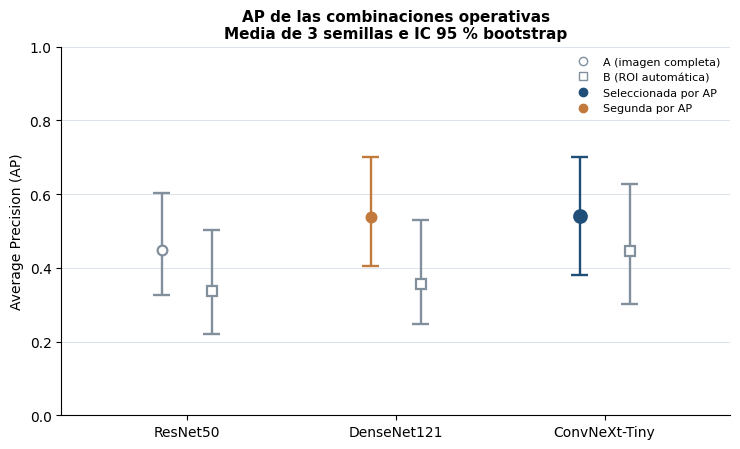

In [9]:
CONDITION_OFFSETS = {"A": -0.12, "B": 0.12}
CONDITION_MARKERS = {"A": "o", "B": "s"}

rows = candidates.set_index(["architecture", "condition"])
positions = np.arange(len(ARCHS))

fig, ax = plt.subplots(figsize=(7.5, 4.6))

for condition in SELECTION_CONDITIONS:
    for position, arch in zip(positions, ARCHS):
        row = rows.loc[(arch, condition)]
        x = position + CONDITION_OFFSETS[condition]

        is_selected = (
            arch == selected["architecture"]
            and condition == selected["condition"]
        )
        is_runner = (
            arch == runner_up["architecture"]
            and condition == runner_up["condition"]
        )

        color = (
            PLOT_COLORS["selected"] if is_selected
            else PLOT_COLORS["runner_up"] if is_runner
            else PLOT_COLORS["other"]
        )

        lower = row["average_precision_ci95_lower"]
        upper = row["average_precision_ci95_upper"]

        ax.vlines(
            x, lower, upper,
            color=color, linewidth=1.7, zorder=2
        )

        ax.hlines(
            [lower, upper],
            x - 0.04, x + 0.04,
            color=color, linewidth=1.7, zorder=2
        )

        ax.plot(
            x,
            row["average_precision_mean"],
            linestyle="none",
            marker=CONDITION_MARKERS[condition],
            markersize=9 if is_selected else 7,
            markerfacecolor=color if (is_selected or is_runner) else "white",
            markeredgecolor=color,
            markeredgewidth=1.6,
            zorder=3,
        )

# Leyenda
for condition in SELECTION_CONDITIONS:
    ax.plot(
        [], [],
        linestyle="none",
        marker=CONDITION_MARKERS[condition],
        markerfacecolor="white",
        markeredgecolor=PLOT_COLORS["other"],
        label=CONDITION_LABELS[condition],
    )

for key, label in [
    ("selected", "Seleccionada por AP"),
    ("runner_up", "Segunda por AP"),
]:
    ax.plot(
        [], [],
        linestyle="none",
        marker="o",
        color=PLOT_COLORS[key],
        label=label,
    )

ax.set_xticks(positions)
ax.set_xticklabels([ARCH_LABELS[a] for a in ARCHS])
ax.set_xlim(-0.6, len(ARCHS) - 0.4)
ax.set_ylim(0, 1)

ax.set_ylabel("Average Precision (AP)")
ax.set_title(
    "AP de las combinaciones operativas\n"
    "Media de 3 semillas e IC 95 % bootstrap",
    fontsize=11,
    fontweight="semibold",
)

ax.grid(axis="y", color=PLOT_COLORS["grid"], linewidth=0.7)
ax.set_axisbelow(True)

for side in ("top", "right"):
    ax.spines[side].set_visible(False)

ax.legend(frameon=False, fontsize=8, loc="upper right")

fig.tight_layout()
fig.savefig(
    FIGURES_DIR / "r6_ap_candidates_ci95.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

### 5.1 Combinación seleccionada frente a la segunda

Valores consolidados de las tres semillas (punto = media; barra = IC 95 % bootstrap de R4/R5) para las dos combinaciones con mayor AP media. **AP es el criterio principal de selección**; ROC-AUC, sensibilidad y especificidad se muestran como criterios complementarios y no modifican la selección.

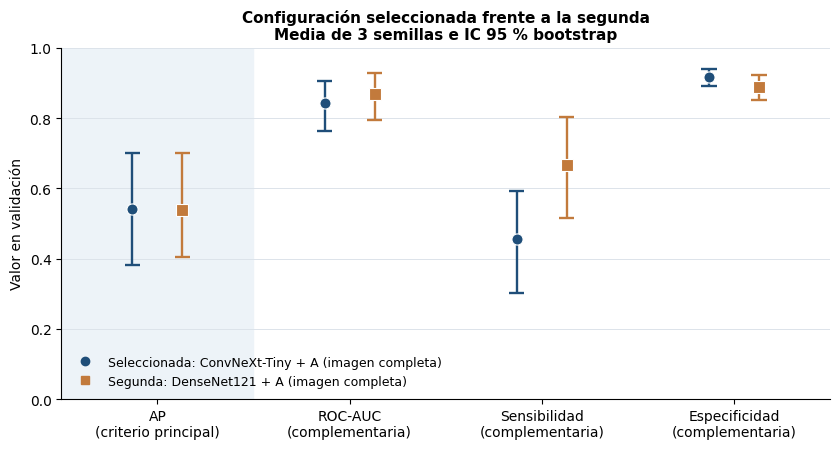

In [10]:
COMPARISON_STYLES = {
    "selected": {
        "offset": -0.13,
        "marker": "o",
        "color": PLOT_COLORS["selected"],
    },
    "runner_up": {
        "offset": 0.13,
        "marker": "s",
        "color": PLOT_COLORS["runner_up"],
    },
}

METRIC_ROLE = {
    "average_precision": "criterio principal",
    "roc_auc": "complementaria",
    "sensitivity": "complementaria",
    "specificity": "complementaria",
}

fig, ax = plt.subplots(figsize=(8.5, 4.6))
positions = np.arange(len(REPORTED_METRICS))

assert REPORTED_METRICS[0] == PRIMARY_METRIC

# Resaltar discretamente la métrica principal
ax.axvspan(-0.5, 0.5, color="#EDF3F8", zorder=0)

for key, row in (
    ("selected", selected),
    ("runner_up", runner_up),
):
    style = COMPARISON_STYLES[key]

    for position, metric in zip(positions, REPORTED_METRICS):
        x = position + style["offset"]

        lower = row[f"{metric}_ci95_lower"]
        upper = row[f"{metric}_ci95_upper"]

        ax.vlines(
            x, lower, upper,
            color=style["color"],
            linewidth=1.7,
            zorder=2,
        )

        ax.hlines(
            [lower, upper],
            x - 0.04, x + 0.04,
            color=style["color"],
            linewidth=1.7,
            zorder=2,
        )

        ax.plot(
            x,
            row[f"{metric}_mean"],
            linestyle="none",
            marker=style["marker"],
            markersize=8,
            markerfacecolor=style["color"],
            markeredgecolor="white",
            markeredgewidth=0.8,
            zorder=3,
        )

    prefix = "Seleccionada" if key == "selected" else "Segunda"

    ax.plot(
        [], [],
        linestyle="none",
        marker=style["marker"],
        color=style["color"],
        label=f"{prefix}: {combination_label(row)}",
    )

ax.set_xticks(positions)
ax.set_xticklabels([
    f"{METRIC_LABELS[m]}\n({METRIC_ROLE[m]})"
    for m in REPORTED_METRICS
])

ax.set_xlim(-0.5, len(REPORTED_METRICS) - 0.5)
ax.set_ylim(0, 1)
ax.set_ylabel("Valor en validación")

ax.set_title(
    "Configuración seleccionada frente a la segunda\n"
    "Media de 3 semillas e IC 95 % bootstrap",
    fontsize=11,
    fontweight="semibold",
)

ax.grid(axis="y", color=PLOT_COLORS["grid"], linewidth=0.7)
ax.set_axisbelow(True)

for side in ("top", "right"):
    ax.spines[side].set_visible(False)

ax.legend(frameon=False, fontsize=9, loc="lower left")

fig.tight_layout()
fig.savefig(
    FIGURES_DIR / "r6_selected_vs_runnerup_metrics.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

### 5.2 Matrices de confusión de la combinación seleccionada

Matrices de confusión en `validation` de cada una de las tres semillas de la combinación seleccionada (ConvNeXt-Tiny + A), calculadas desde las predicciones guardadas del checkpoint de cada corrida con el umbral fijo 0.5. No se elige una semilla representativa ni se combinan probabilidades entre semillas: la figura muestra la variabilidad del comportamiento al umbral entre las tres ejecuciones. Los recuentos se contrastan con los de `r5_metrics_per_seed.csv`.

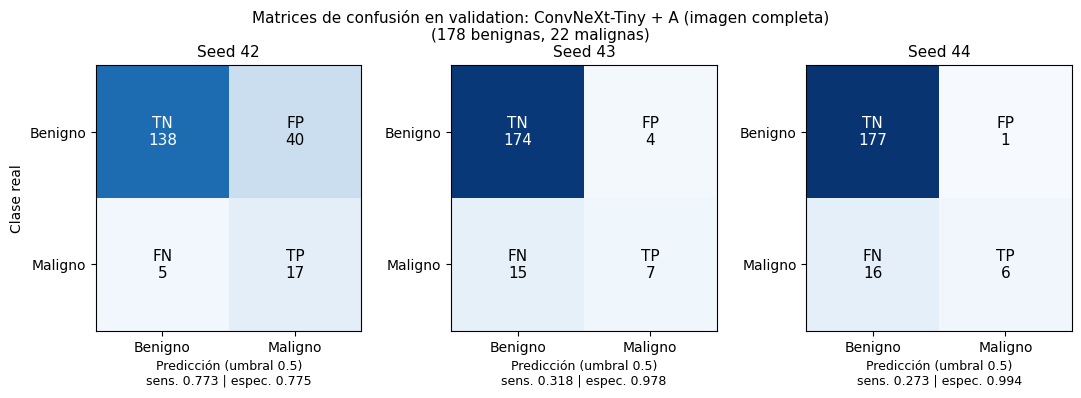

In [11]:
confusion = {}

for seed in SEEDS:
    predictions = selected_predictions[seed]

    y_true = predictions["y_true"].to_numpy()
    y_pred = (predictions["probability_malignant"].to_numpy() >= THRESHOLD).astype(int)

    tn = int(((y_true == 0) & (y_pred == 0)).sum())
    fp = int(((y_true == 0) & (y_pred == 1)).sum())
    fn = int(((y_true == 1) & (y_pred == 0)).sum())
    tp = int(((y_true == 1) & (y_pred == 1)).sum())

    # Contraste con los resultados consolidados de R4/R5
    consolidated = r5_per_seed[
        (r5_per_seed["architecture"] == selected_arch)
        & (r5_per_seed["condition"] == selected_condition)
        & (r5_per_seed["seed"] == seed)
    ]
    assert len(consolidated) == 1
    assert (tn, fp, fn, tp) == tuple(int(consolidated[k].iloc[0]) for k in ["tn", "fp", "fn", "tp"]), seed

    confusion[seed] = np.array([[tn, fp], [fn, tp]])

fig, axes = plt.subplots(1, len(SEEDS), figsize=(11.0, 3.8))

for ax, seed in zip(axes, SEEDS):
    matrix = confusion[seed]
    ax.imshow(matrix, cmap="Blues", vmin=0, vmax=180)

    cell_names = [["TN", "FP"], ["FN", "TP"]]
    for i in range(2):
        for j in range(2):
            value = matrix[i, j]
            ax.text(j, i, f"{cell_names[i][j]}\n{value}", ha="center", va="center", fontsize=11,
                    color="white" if value > 100 else "black")

    sensitivity = matrix[1, 1] / matrix[1].sum()
    specificity = matrix[0, 0] / matrix[0].sum()

    ax.set_xticks([0, 1])
    ax.set_xticklabels(CLASS_LABELS)
    ax.set_yticks([0, 1])
    ax.set_yticklabels(CLASS_LABELS)
    ax.set_xlabel(f"Predicción (umbral {THRESHOLD})\nsens. {sensitivity:.3f} | espec. {specificity:.3f}", fontsize=9)
    ax.set_title(f"Seed {seed}", fontsize=11)

axes[0].set_ylabel("Clase real")
fig.suptitle(
    f"Matrices de confusión en validation: {combination_label(selected)}\n(178 benignas, 22 malignas)",
    fontsize=11,
)

fig.tight_layout()
fig.savefig(FIGURES_DIR / "r6_selected_confusion_matrices.png", dpi=300, bbox_inches="tight")
plt.show()

## 6. Regla aplicada y criterios alternativos

La regla aplicada es la del protocolo de R6 y la del IOV aprobado: mayor AP media en `validation` entre semillas. Con ella se selecciona ConvNeXt-Tiny + A. No se produjo un empate exacto en AP; no se aplicó ningún criterio de desempate.

El criterio ROC-AUC media se evaluó como criterio alternativo: con él se habría seleccionado DenseNet121 + A (campo `sensitivity_criterion` de `r6_selection.json`). Ese criterio no modifica la selección. Los resultados de un análisis previo con el criterio ROC-AUC se conservan como material histórico en `results/classification/r6_model_selection/historico/`.

## 7. Curvas de entrenamiento de la combinación seleccionada

En cada curva se marca la época del checkpoint, que es la de máxima `val_roc_auc` según `best_auc_meta.json` (el early stopping se basa en `val_weighted_loss`, con paciencia 5). La pérdida graficada es la ponderada por clase que registra el historial. No se utiliza accuracy.

In [13]:
HISTORY_KEYS = ["train_loss", "val_loss", "val_roc_auc", "val_average_precision"]

histories, checkpoint_epochs, curve_rows = {}, {}, []

for seed in SEEDS:
    seed_dir = CLASSIFICATION_DIR / "r4_benchmark" / selected_arch / selected_condition / f"seed_{seed}"
    with open(seed_dir / "training_history.json", encoding="utf-8") as f:
        history = json.load(f)
    with open(seed_dir / "best_auc_meta.json", encoding="utf-8") as f:
        best_meta = json.load(f)
    with open(seed_dir / "run_config.json", encoding="utf-8") as f:
        run_config = json.load(f)

    n_epochs = len(history["train_loss"])
    assert n_epochs == run_config["epochs_run"], seed
    for key in HISTORY_KEYS:
        assert len(history[key]) == n_epochs, (seed, key)

    # Las épocas se numeran desde 1; el checkpoint es el máximo de val_roc_auc
    epoch_best = best_meta["epoch"]
    assert epoch_best == run_config["epoch_best"], seed
    index_best = epoch_best - 1

    # Primera época desde la cual val_loss permanece por encima de train_loss hasta el final de la corrida
    persistent_gap_epoch = None
    for index in range(n_epochs - 1, -1, -1):
        if history["val_loss"][index] > history["train_loss"][index]:
            persistent_gap_epoch = index + 1
        else:
            break

    histories[seed] = history
    checkpoint_epochs[seed] = epoch_best
    curve_rows.append(
        {
            "seed": seed,
            "epochs_run": n_epochs,
            "checkpoint_epoch": epoch_best,
            "early_stopped": bool(run_config["early_stopped"]),
            "early_stopped_at_epoch": run_config.get("early_stopped_at_epoch"),
            "train_loss_last": history["train_loss"][-1],
            "val_loss_last": history["val_loss"][-1],
            "train_loss_checkpoint": history["train_loss"][index_best],
            "val_loss_checkpoint": history["val_loss"][index_best],
            "val_roc_auc_checkpoint": history["val_roc_auc"][index_best],
            "val_average_precision_checkpoint": history["val_average_precision"][index_best],
            "min_val_loss_epoch": int(np.argmin(history["val_loss"])) + 1,
            "persistent_gap_from_epoch": persistent_gap_epoch,
        }
    )

curves_summary = pd.DataFrame(curve_rows)
curves_summary.to_csv(OUTPUT_DIR / "r6_curvas_resumen.csv", index=False)

curves_table = pd.DataFrame(
    {
        "Semilla": curves_summary["seed"],
        "Épocas ejecutadas": curves_summary["epochs_run"],
        "Época del checkpoint": curves_summary["checkpoint_epoch"],
        "Early stopping": curves_summary.apply(
            lambda row: f"sí (época {row['early_stopped_at_epoch']})" if row["early_stopped"] else "no", axis=1
        ),
        "train_loss última": curves_summary["train_loss_last"].round(3),
        "val_loss última": curves_summary["val_loss_last"].round(3),
        "train_loss checkpoint": curves_summary["train_loss_checkpoint"].round(3),
        "val_loss checkpoint": curves_summary["val_loss_checkpoint"].round(3),
        "Época de mínimo val_loss": curves_summary["min_val_loss_epoch"],
        "val_loss > train_loss hasta el final desde la época": curves_summary["persistent_gap_from_epoch"],
    }
)

curves_table

,Semilla,Épocas ejecutadas,Época del checkpoint,Early stopping,train_loss última,val_loss última,train_loss checkpoint,val_loss checkpoint,Época de mínimo val_loss,val_loss > train_loss hasta el final desde la época
0,42,13,8,sí (época 13),0.054,1.700,0.210,0.432,8,3
1,43,8,7,sí (época 8),0.140,0.723,0.216,1.142,3,2
2,44,8,7,sí (época 8),0.109,0.989,0.203,1.248,3,2


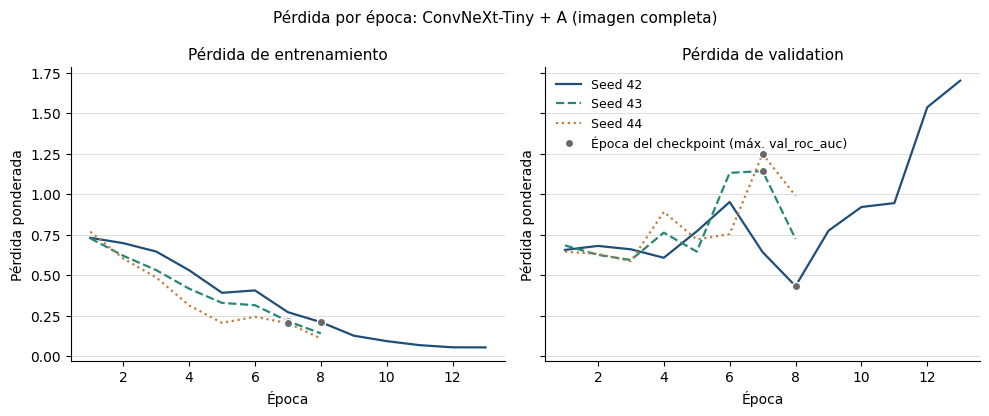

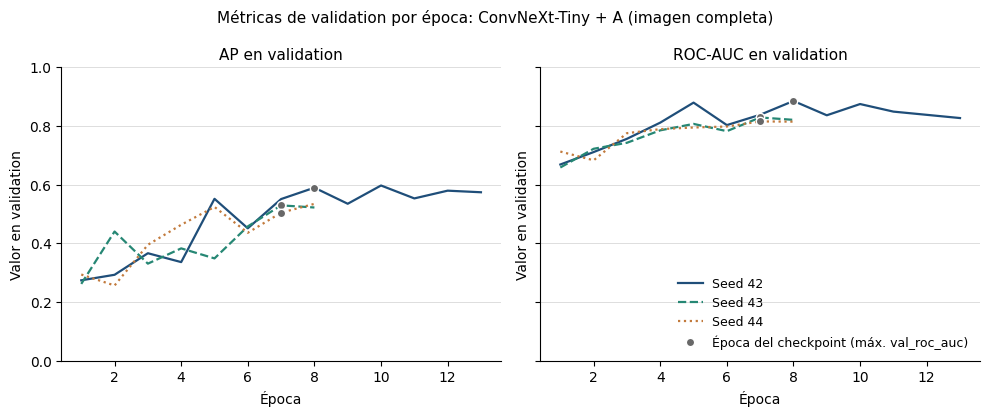

Seed 42: val_loss permanece por encima de train_loss desde la época 3; checkpoint en la época 8 de 13; mínimo de val_loss en la época 8.
Seed 43: val_loss permanece por encima de train_loss desde la época 2; checkpoint en la época 7 de 8; mínimo de val_loss en la época 3.
Seed 44: val_loss permanece por encima de train_loss desde la época 2; checkpoint en la época 7 de 8; mínimo de val_loss en la época 3.


In [17]:
SEED_STYLES = {
    42: { "color": PLOT_COLORS["seed"][42], "linestyle": "-", },
    43: { "color": PLOT_COLORS["seed"][43], "linestyle": "--", },
    44: { "color": PLOT_COLORS["seed"][44], "linestyle": ":", },
}


def plot_curve(ax, seed, key):
    style = SEED_STYLES[seed]
    values = histories[seed][key]
    epochs = np.arange(1, len(values) + 1)
    ax.plot(epochs, values, color=style["color"], linestyle=style["linestyle"], linewidth=1.6, label=f"Seed {seed}")
    best = checkpoint_epochs[seed]
    ax.plot( best, values[best - 1], linestyle="none", marker="o", markersize=6, markerfacecolor="#686868", 
            markeredgecolor="white", markeredgewidth=1, zorder=4, )


def style_curve_axis(ax, title, ylabel):
    ax.set_title(title, fontsize=11)
    ax.set_xlabel("Época")
    ax.set_ylabel(ylabel)
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
    ax.grid(axis="y", color="#dddddd", linewidth=0.7, zorder=0)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)


checkpoint_handle = plt.Line2D([], [], linestyle="none", marker="o", markersize=6, markerfacecolor="#686868",
                               markeredgecolor="white", label="Época del checkpoint (máx. val_roc_auc)")

# Figura 1: pérdida de entrenamiento y de validation
fig, axes = plt.subplots(1, 2, figsize=(10.0, 4.2), sharey=True)
for seed in SEEDS:
    plot_curve(axes[0], seed, "train_loss")
    plot_curve(axes[1], seed, "val_loss")
style_curve_axis(axes[0], "Pérdida de entrenamiento", "Pérdida ponderada")
style_curve_axis(axes[1], "Pérdida de validation", "Pérdida ponderada")
handles, labels = axes[1].get_legend_handles_labels()
axes[1].legend(handles + [checkpoint_handle], labels + [checkpoint_handle.get_label()], frameon=False, fontsize=9, loc="upper left")
fig.suptitle(f"Pérdida por época: {combination_label(selected)}", fontsize=11)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "r6_curvas_entrenamiento_loss.png", dpi=300, bbox_inches="tight")
plt.show()

# Figura 2: AP y ROC-AUC en validation
fig, axes = plt.subplots(1, 2, figsize=(10.0, 4.2), sharey=True)
for seed in SEEDS:
    plot_curve(axes[0], seed, "val_average_precision")
    plot_curve(axes[1], seed, "val_roc_auc")
style_curve_axis(axes[0], "AP en validation", "Valor en validation")
style_curve_axis(axes[1], "ROC-AUC en validation", "Valor en validation")
axes[0].set_ylim(0, 1)
handles, labels = axes[1].get_legend_handles_labels()
axes[1].legend(handles + [checkpoint_handle], labels + [checkpoint_handle.get_label()], frameon=False, fontsize=9, loc="lower right")
fig.suptitle(f"Métricas de validation por época: {combination_label(selected)}", fontsize=11)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "r6_curvas_entrenamiento_metricas.png", dpi=300, bbox_inches="tight")
plt.show()

for row in curve_rows:
    gap = row["persistent_gap_from_epoch"]
    gap_text = f"desde la época {gap}" if gap is not None else "no de forma sostenida hasta el final"
    print(
        f"Seed {row['seed']}: val_loss permanece por encima de train_loss {gap_text}; "
        f"checkpoint en la época {row['checkpoint_epoch']} de {row['epochs_run']}; mínimo de val_loss en la época {row['min_val_loss_epoch']}."
    )

### 7.1 Lectura descriptiva de las curvas

- La tabla y las líneas impresas indican, para cada semilla, desde qué época `val_loss` queda por encima de `train_loss` hasta el final de la corrida. Es una descripción de las curvas, no una prueba de sobreajuste.
- El checkpoint se eligió por máxima `val_roc_auc`, no por pérdida; por eso su época no coincide necesariamente con el mínimo de `val_loss` (columna "Época de mínimo val_loss").
- Las curvas provienen de una sola corrida por semilla y de un `validation` con 22 casos malignos; AP y ROC-AUC por época fluctúan en esa escala. Los datos no permiten atribuir la separación entre pérdidas a una causa concreta.

## 8. Registro formal de la selección

Se guarda un registro con la combinación seleccionada, la regla aplicada, sus valores y las fuentes utilizadas.

In [12]:
def metric_record(row):
    return {
        metric: {
            "mean": float(row[f"{metric}_mean"]),
            "std_between_seeds": float(row[f"{metric}_std_between_seeds"]),
            "ci95_lower": float(row[f"{metric}_ci95_lower"]),
            "ci95_upper": float(row[f"{metric}_ci95_upper"]),
        }
        for metric in REPORTED_METRICS
    }


# Combinación con mayor ROC-AUC media (criterio alternativo, no modifica la selección)
roc_top = candidates.loc[candidates["roc_auc_mean"].idxmax()]

selection_record = {
    "selected": {
        "architecture": selected["architecture"],
        "condition": selected["condition"],
        "metrics_validation": metric_record(selected),
    },
    "runner_up": {
        "architecture": runner_up["architecture"],
        "condition": runner_up["condition"],
        "metrics_validation": metric_record(runner_up),
    },
    "selection_rule": {
        "primary_criterion": "max mean Average Precision on validation (mean of 3 seeds)",
        "iov_reference": "La configuración seleccionada es la de mayor AP media entre semillas, con criterio de desempate definido antes de ejecutar.",
        "complementary_criteria": ["roc_auc", "std_between_seeds", "sensitivity", "specificity"],
        "excluded_criteria": ["accuracy (class imbalance)"],
        "candidate_conditions": SELECTION_CONDITIONS,
        "excluded_conditions": {"C": "requires reference mask; idealized condition in R5"},
        "candidate_architectures": ARCHS,
        "seeds": SEEDS,
        "threshold": THRESHOLD,
    },
    "sensitivity_criterion": {
        "metric": "mean ROC-AUC",
        "would_select": f"{roc_top['architecture']}-{roc_top['condition']}",
    },
    "data": {
        "evaluation_split": "validation",
        "n_validation": 200,
        "n_malignant_validation": 22,
        "test_used": False,
        "new_training": False,
    },
    "sources": [
        str((R4_DIR / "r4_architecture_summary.csv").relative_to(PROJECT_ROOT)),
        str((R5_DIR / "r5_condition_summary.csv").relative_to(PROJECT_ROOT)),
        str((R5_DIR / "r5_metrics_per_seed.csv").relative_to(PROJECT_ROOT)),
        str(SPLIT_MANIFEST.relative_to(PROJECT_ROOT)),
        "results/classification/r4_benchmark/convnext_tiny/A/seed_*/val_predictions_best_auc.csv",
        "results/classification/r4_benchmark/convnext_tiny/A/seed_*/training_history.json",
        "results/classification/r4_benchmark/convnext_tiny/A/seed_*/best_auc_meta.json",
        "results/classification/r4_benchmark/convnext_tiny/A/seed_*/run_config.json",
    ],
}

with open(OUTPUT_DIR / "r6_selection.json", "w", encoding="utf-8") as f:
    json.dump(selection_record, f, indent=2, ensure_ascii=False)

print(json.dumps(selection_record["selected"], indent=2, ensure_ascii=False))

{
  "architecture": "convnext_tiny",
  "condition": "A",
  "metrics_validation": {
    "average_precision": {
      "mean": 0.5412919866684299,
      "std_between_seeds": 0.0438030649054456,
      "ci95_lower": 0.3812596960044144,
      "ci95_upper": 0.699746296523108
    },
    "roc_auc": {
      "mean": 0.8433775961865849,
      "std_between_seeds": 0.0369670645416345,
      "ci95_lower": 0.7625936329588014,
      "ci95_upper": 0.9047667688117124
    },
    "sensitivity": {
      "mean": 0.4545454545454545,
      "std_between_seeds": 0.2764892059226463,
      "ci95_lower": 0.303030303030303,
      "ci95_upper": 0.5909090909090909
    },
    "specificity": {
      "mean": 0.9157303370786516,
      "std_between_seeds": 0.1219243506416331,
      "ci95_lower": 0.8913857677902621,
      "ci95_upper": 0.9382022471910112
    }
  }
}
